# 02 - Exploratory data analysis

Inputs: `train` and `student_test`. Label-based analysis (alignment of GPS to the reference route) uses `train` only.
Regenerate the tables and figures with `python scripts/run_eda.py`; the findings are written up in `reports/data_quality_log.md`.

In [1]:
import os, sys
from pathlib import Path
# run from the repository root so relative paths in configs work
if Path.cwd().name == "notebooks":
    os.chdir("..")
import numpy as np
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.max_columns", 60)

## Raw files of one trip

In [2]:
from pathsnap.data.loader import load_trip
from pathsnap.data.validation import validate_trip
trip = load_trip("train", "00000001")
display(trip.track.head(), trip.nodes.head(), trip.arcs.head(), trip.route.head())
validate_trip(trip)

,lon,lat,timestamp
obs_id,,,
0,8.595203,49.844053,1.0
1,8.595294,49.844441,2.0
2,8.595352,49.844883,3.0
3,8.595390,49.845379,4.0
4,8.595587,49.845750,5.0


,lon,lat
node_id,,
0,8.581679,49.857880
1,8.584637,49.858295
2,8.580173,49.858567
3,8.584392,49.859119
4,8.584935,49.857396


,from_node,to_node
arc_id,,
0,0,281
1,0,1
2,0,5
3,1,0
4,1,40750


,arc_id
route_pos,
0,2641
1,64973
2,133948
3,133949
4,139208


{'trip_id': '00000001',
 'partition': 'train',
 'n_obs': 1315,
 'n_missing_values': 0,
 'n_out_of_range_coords': 0,
 'n_duplicate_rows': 0,
 'n_duplicate_positions': 0,
 'n_duplicate_timestamps': 0,
 'n_non_increasing_steps': 0,
 'timestamps_sorted': True,
 'duration_s': 1357.0,
 'dt_median_s': 1.0,
 'dt_max_s': 16.0,
 'share_dt_eq_1s': 0.9809741248097412,
 'n_gaps_gt_5s': 1,
 'n_gaps_gt_30s': 0,
 'n_nodes': 88809,
 'n_arcs': 165790,
 'n_missing_node_values': 0,
 'n_out_of_range_node_coords': 0,
 'n_duplicate_node_coords': 8,
 'n_arcs_invalid_node_ref': 0,
 'n_self_loops': 0,
 'n_duplicate_arcs': 292,
 'has_route': True,
 'route_len': 525,
 'route_n_unique_arcs': 525,
 'route_n_invalid_arc_ids': 0,
 'route_n_repeated_consecutive': 0,
 'route_n_breaks': 0,
 'route_share_connected': 1.0}

## Data quality per trip

In [3]:
q = pd.read_csv("results/data_quality.csv", dtype={"trip_id": str})
q.groupby("partition")[["n_obs", "duration_s", "dt_max_s", "share_dt_eq_1s", "n_gaps_gt_30s",
                        "n_nodes", "n_arcs", "n_weak_components", "largest_weak_component_share",
                        "share_arcs_two_way", "route_len", "route_n_breaks", "share_stationary"]].describe().T

partition               student_test        train
n_obs            count     10.000000    80.000000
                 mean    1916.000000  2605.212500
                 std     1335.432348  3312.345399
                 min      262.000000   361.000000
                 25%      917.750000   945.750000
...                              ...          ...
share_stationary min        0.000000     0.000000
                 25%        0.007324     0.001484
                 50%        0.024459     0.026223
                 75%        0.052402     0.117853
                 max        0.355408     0.836328

[104 rows x 2 columns]

In [4]:
q.sort_values("dt_max_s", ascending=False)[["partition", "trip_id", "n_obs", "dt_max_s", "n_gaps_gt_30s"]].head(8)

,partition,trip_id,n_obs,dt_max_s,n_gaps_gt_30s
72,train,00000090,536,153064,1
61,train,00000078,2909,52810,2
55,train,00000069,2067,2658,2
16,train,00000021,15783,2161,2
8,train,00000011,2828,909,1
34,train,00000042,7739,670,22
64,train,00000081,3224,536,37
18,train,00000024,801,458,2


## Figures

eda_obs_per_trip


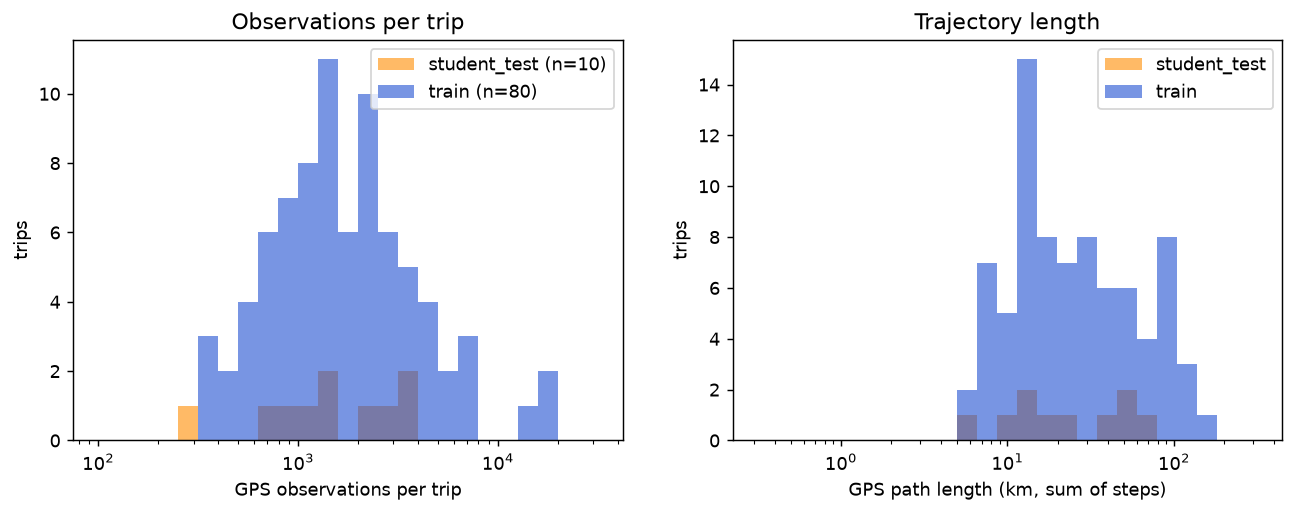

eda_sampling_intervals


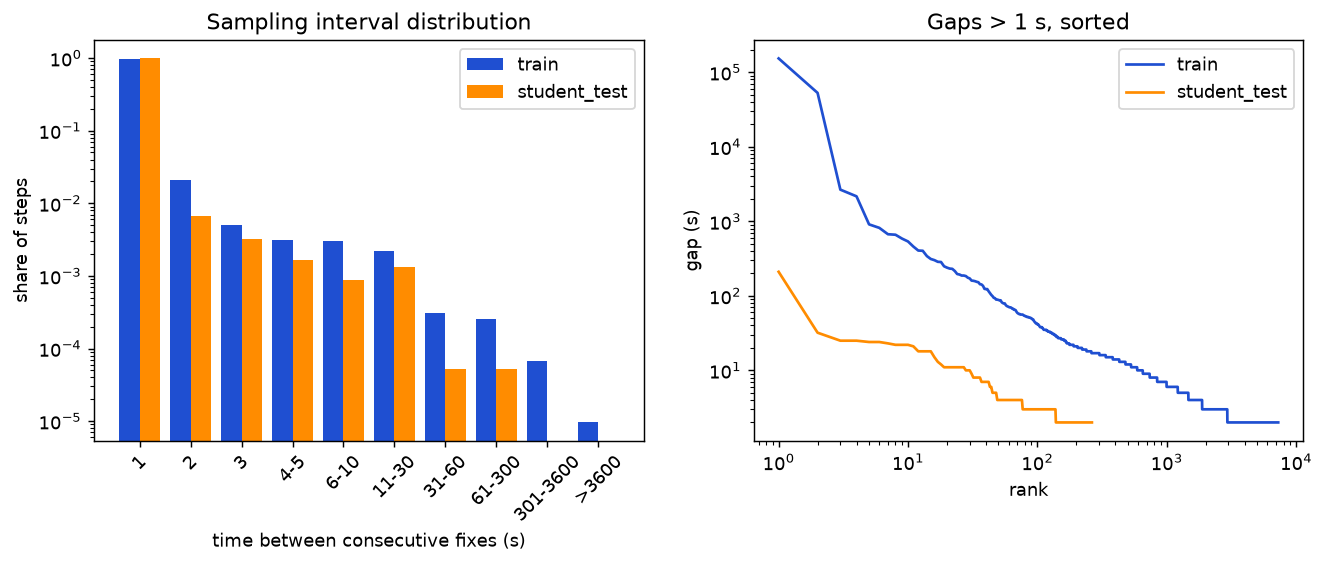

eda_trip_locations


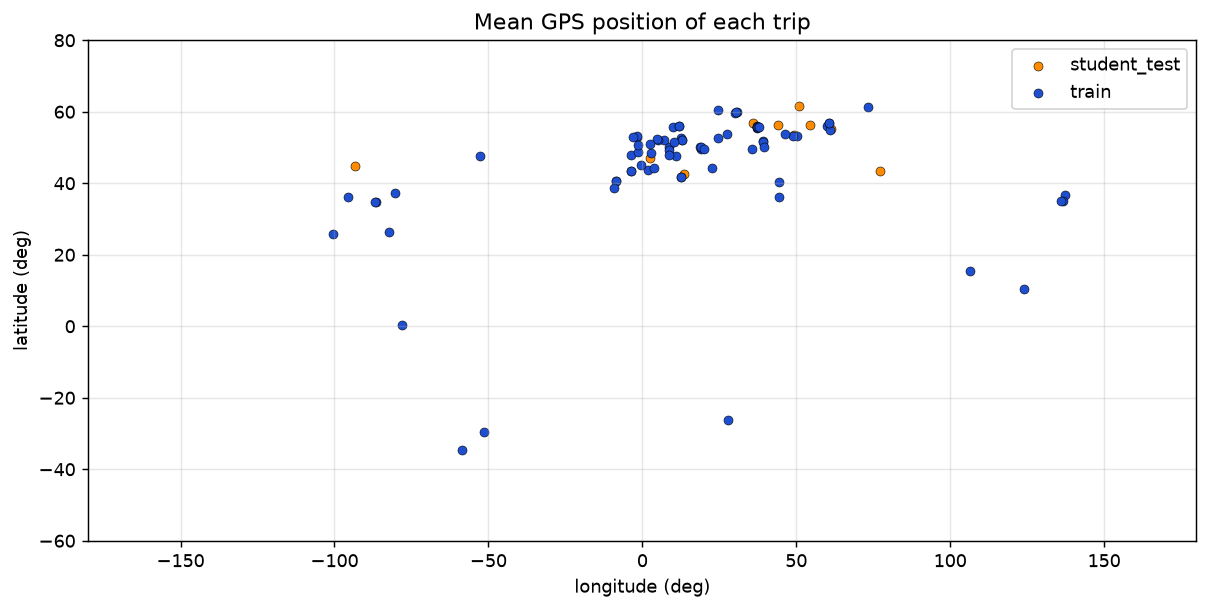

eda_trajectory_grid


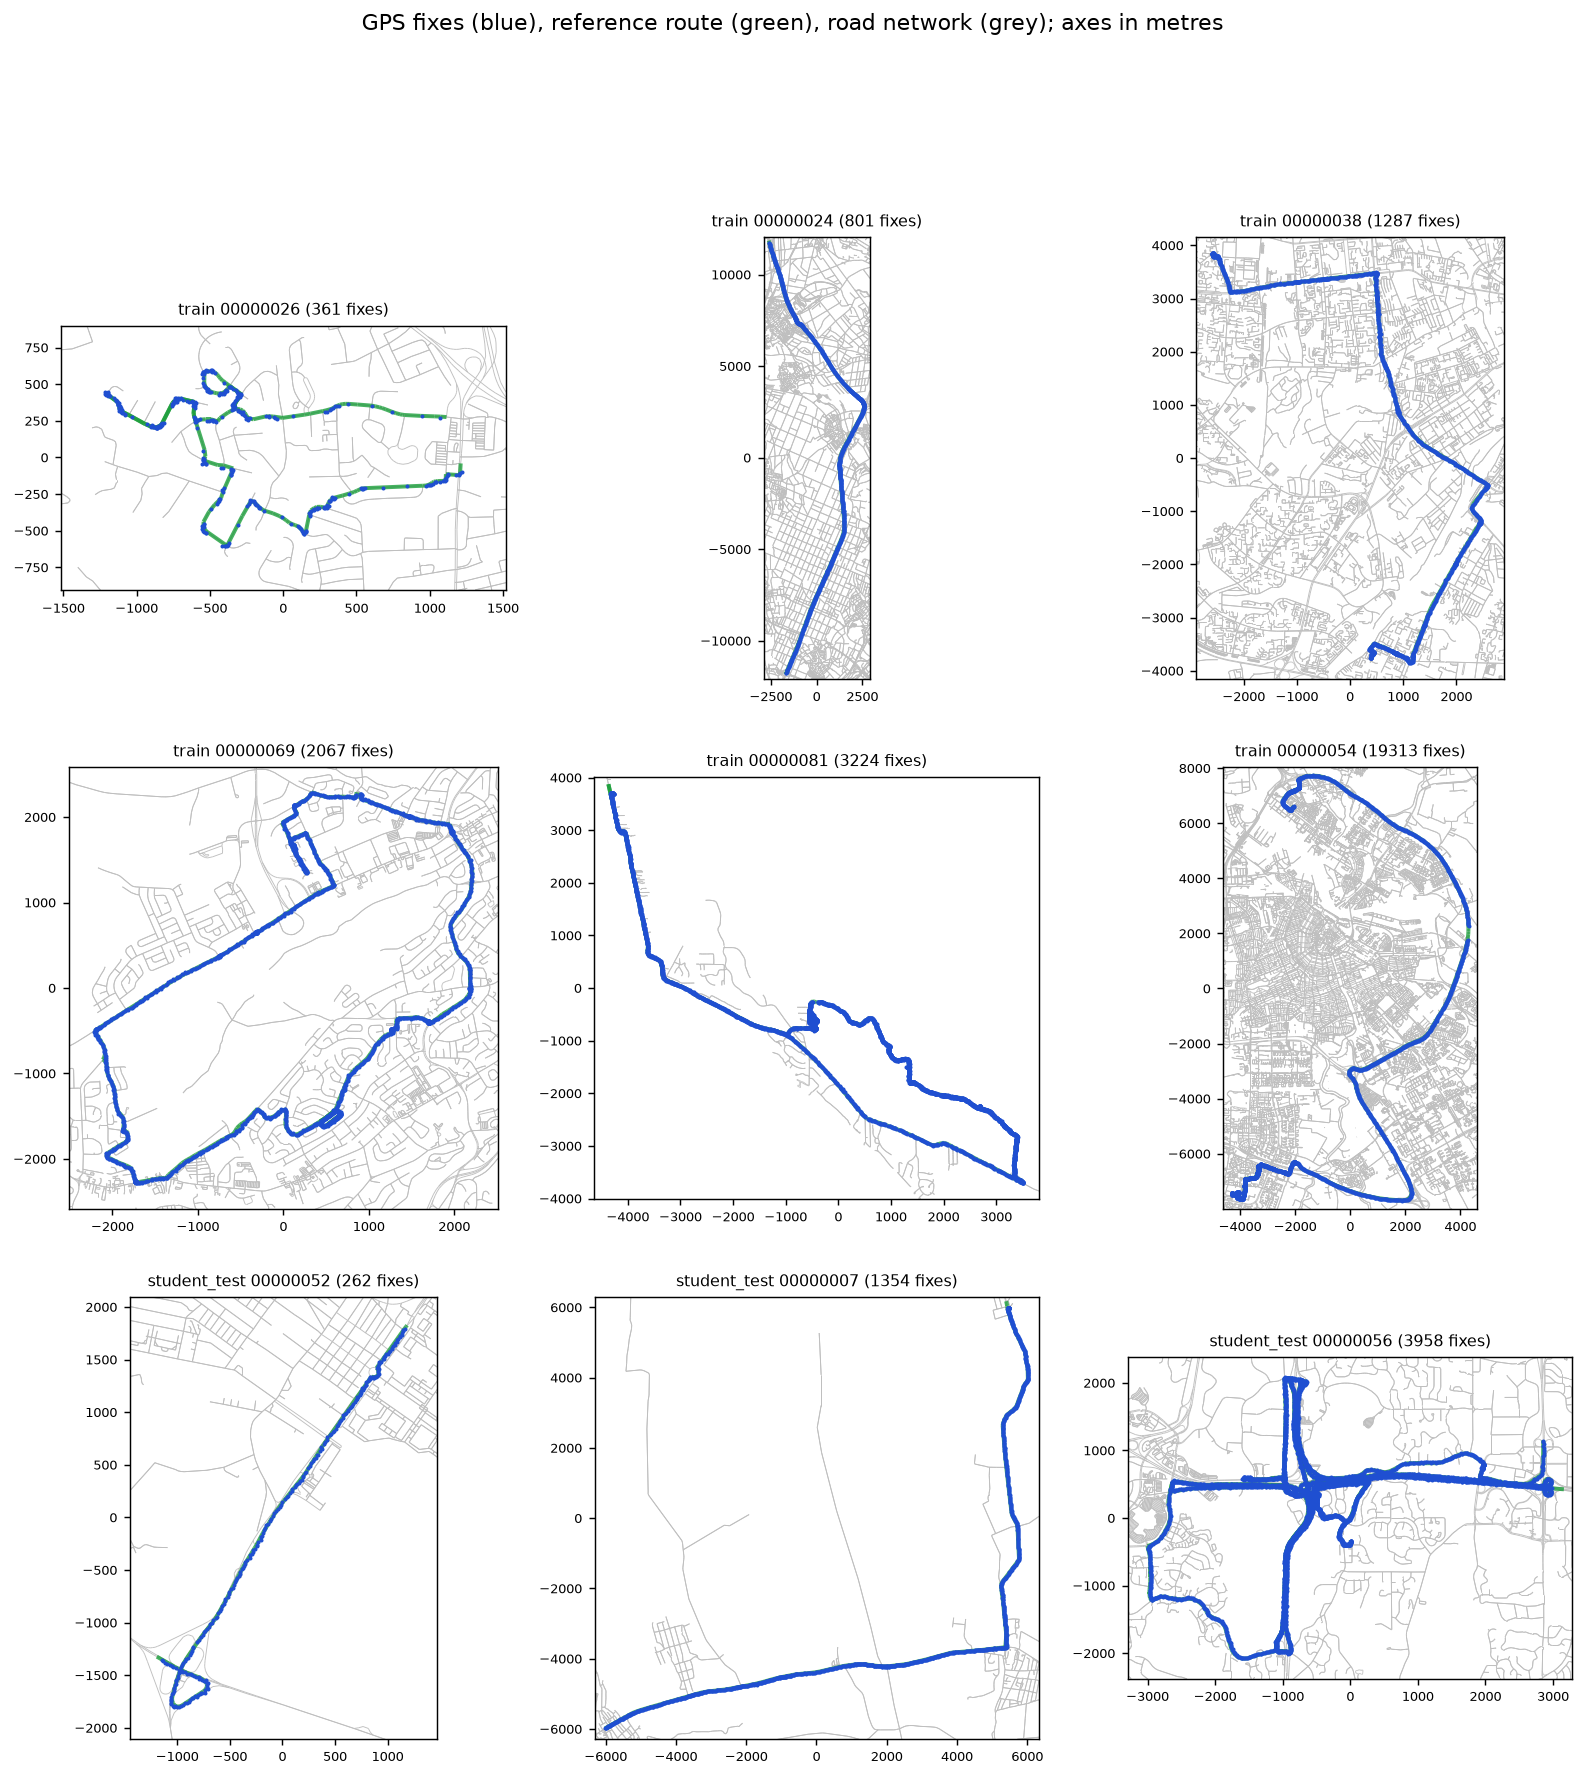

eda_network_size_connectivity


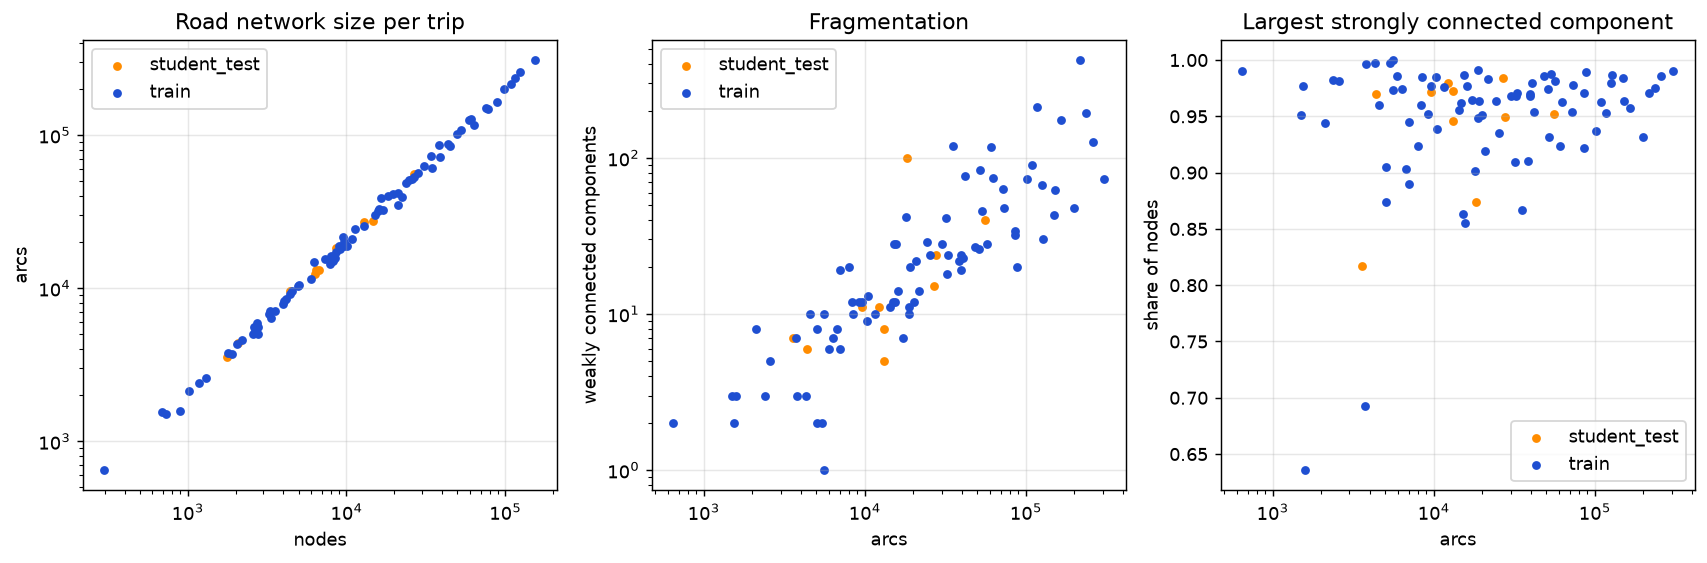

eda_train_alignment_distance


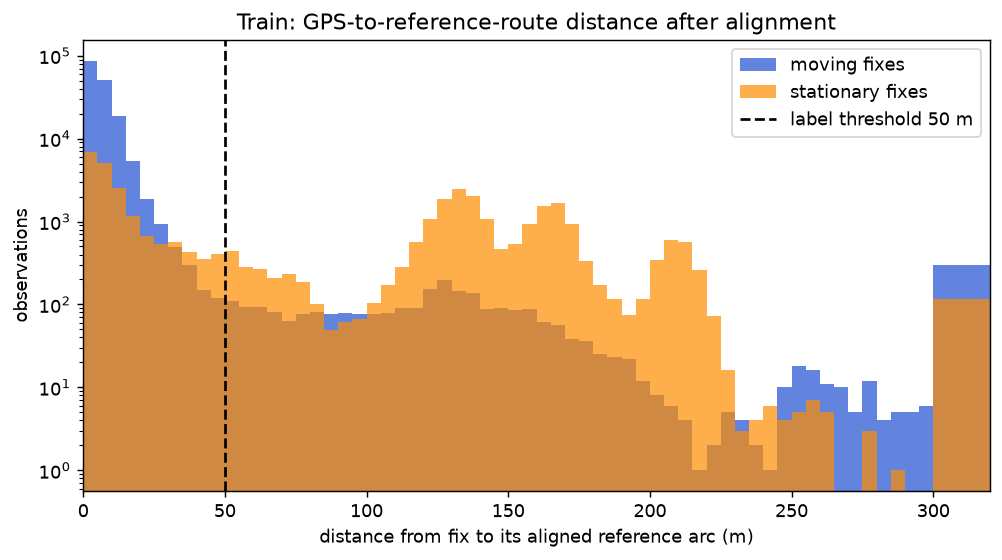

eda_train_candidate_sweep


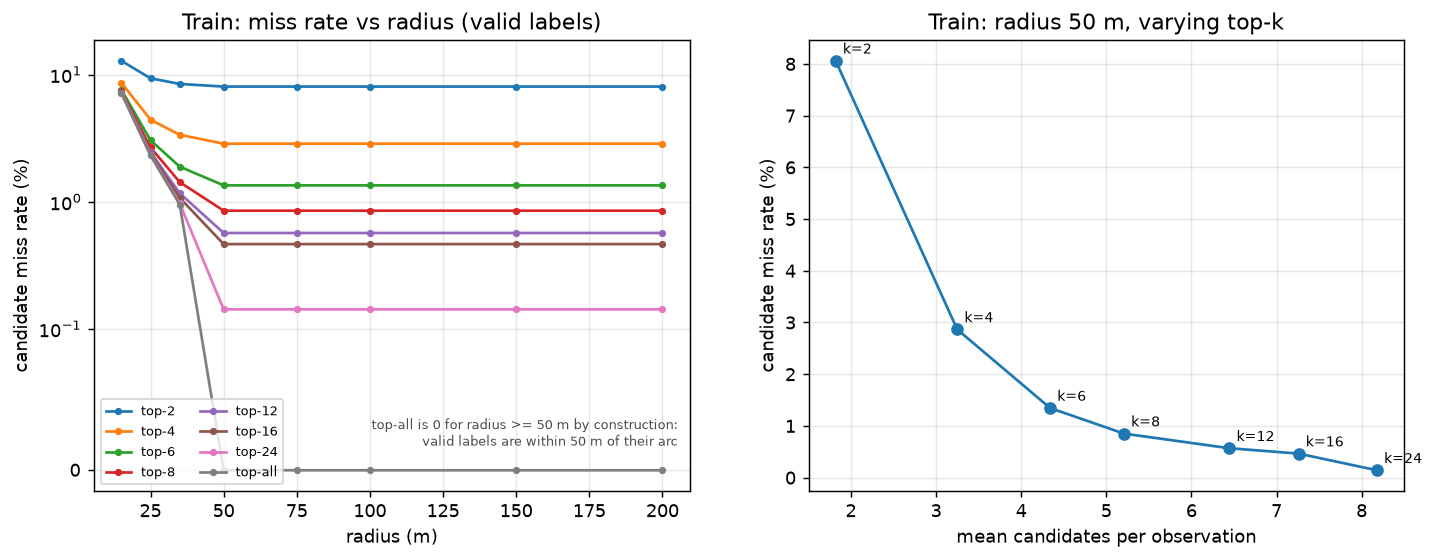

In [5]:
for f in ["eda_obs_per_trip", "eda_sampling_intervals", "eda_trip_locations", "eda_trajectory_grid",
          "eda_network_size_connectivity", "eda_train_alignment_distance", "eda_train_candidate_sweep"]:
    print(f); display(Image(f"results/figures/{f}.png"))

## Projection check (local equirectangular vs haversine)

In [6]:
pd.read_csv("results/projection_check.csv").describe()

,trip_id,network_extent_x_km,network_extent_y_km,arc_len_rel_err_median,arc_len_rel_err_max
count,90.000000,90.000000,90.000000,9.000000e+01,90.000000
mean,49.288889,14.987201,13.875743,2.062603e-04,0.001213
std,29.156010,15.800809,14.167315,2.529488e-04,0.001298
min,0.000000,2.085940,3.040960,3.543370e-07,0.000003
25%,25.250000,4.646323,5.461655,5.925530e-05,0.000424
50%,49.000000,8.303955,7.468030,1.049280e-04,0.000774
75%,74.750000,17.623775,15.942975,2.362503e-04,0.001438
max,99.000000,71.601400,77.634800,1.485110e-03,0.006952


## Fixes far from the reference route (train)

In [7]:
q[q.partition == "train"].sort_values("share_label_excluded", ascending=False)[
    ["trip_id", "n_obs", "share_label_excluded", "share_stationary", "align_dist_p50_m", "align_dist_p95_m"]].head(8)

,trip_id,n_obs,share_label_excluded,share_stationary,align_dist_p50_m,align_dist_p95_m
44,00000054,19313,0.894423,0.836328,140.00800,209.4270
26,00000033,5844,0.588638,0.828029,122.38300,142.0220
1,00000002,7243,0.119840,0.183211,5.76597,242.2300
53,00000066,4325,0.090173,0.092948,6.59022,65.3884
35,00000043,2322,0.071059,0.123600,11.00790,70.0911
76,00000096,3271,0.044329,0.204525,4.46243,20.2797
64,00000081,3224,0.044045,0.025744,4.54641,44.5965
67,00000084,16031,0.036991,0.253571,6.58174,36.3030


## Candidate generation

In [8]:
sweep = pd.read_csv("results/candidate_sweep.csv")
sweep.pivot(index="radius_m", columns="top_k", values="candidate_miss_rate").round(4)

top_k,12,16,2,24,4,6,8,all
radius_m,,,,,,,,
15,0.0729,0.0726,0.1286,0.0720,0.0866,0.0763,0.0741,0.0720
25,0.0246,0.0240,0.0936,0.0233,0.0442,0.0305,0.0268,0.0232
35,0.0117,0.0107,0.0846,0.0097,0.0337,0.0189,0.0143,0.0095
50,0.0057,0.0046,0.0806,0.0014,0.0287,0.0135,0.0085,0.0000
75,0.0057,0.0046,0.0806,0.0014,0.0287,0.0135,0.0085,0.0000
100,0.0057,0.0046,0.0806,0.0014,0.0287,0.0135,0.0085,0.0000
150,0.0057,0.0046,0.0806,0.0014,0.0287,0.0135,0.0085,0.0000
200,0.0057,0.0046,0.0806,0.0014,0.0287,0.0135,0.0085,0.0000


In [9]:
pd.read_csv("results/candidate_miss_rate_summary.csv", index_col=0).T

partition,student_test,train
trips,10.000000,80.000000
n_label_valid,19133.000000,185162.000000
n_label_excluded,27.000000,23255.000000
pooled_miss_rate,0.000732,0.005687
median_trip_miss_rate,0.000000,0.000000
max_trip_miss_rate,0.006673,0.200499
pooled_share_nearest_is_ref,0.521246,0.561805
obs_without_candidates,0.000000,0.000000
obs_used_fallback,0.000000,18229.000000
mean_candidates_per_obs,7.675370,6.853880


## Folium map

Interactive maps are in `maps/html/`. This renders one inline.

In [10]:
import folium
from pathsnap.graph.road_graph import RoadGraph
from pathsnap.visualisation.folium_maps import trip_map
t = load_trip("train", "00000095")
g = RoadGraph.from_trip(t)
trip_map(g, t.track[["lon", "lat"]].to_numpy(), reference_arcs=t.route["arc_id"].to_numpy(), title="train 00000095")